# Monte Carlo path costs with uncertainty

The same seed-0 draws and distributions as `monte-carlo-methods.ipynb`. Bars show 1.96 estimated standard errors of the mean, not the spread of individual costs.


## Synthetic path costs with Monte Carlo uncertainty

This additional figure uses the same seed-0 samples as the printed path-cost example. Error bars show 1.96 times the estimated standard error of the mean, not the spread of individual path outcomes.


{
  "means": [
    9.909486585019609,
    12.013616940316162,
    8.846314309002985
  ],
  "standard_errors": [
    0.06245669430823672,
    0.030631226327215315,
    0.09056076392644304
  ],
  "half_widths": [
    0.12241512084414397,
    0.060037203601342015,
    0.17749909729582836
  ],
  "sample_count": 1000,
  "seed": 0
}


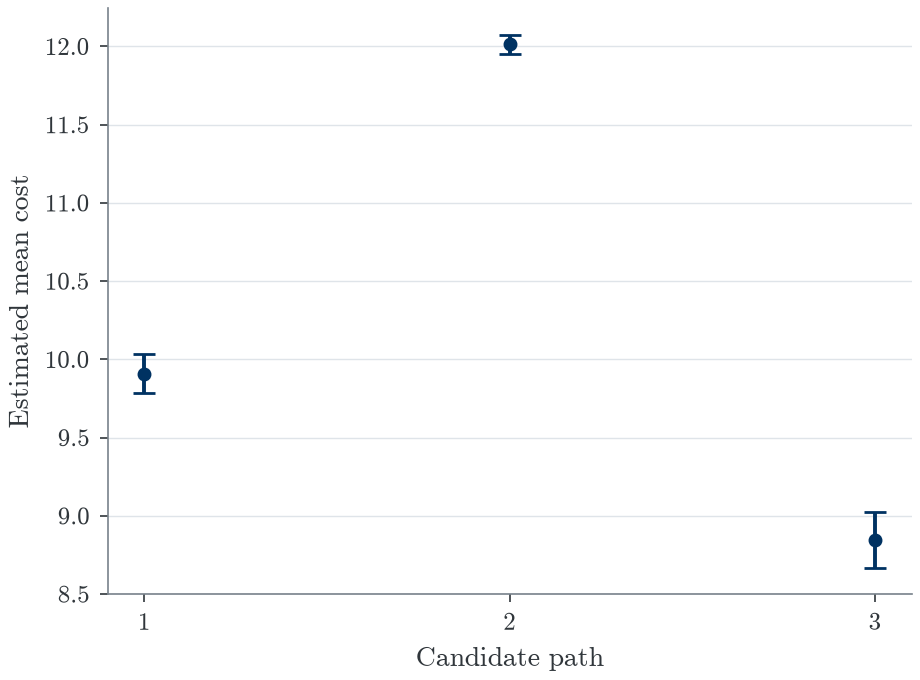

In [1]:
from pathlib import Path
import json, logging
from IPython.display import Image, display
logging.getLogger("fontTools.ttLib.tables._h_e_a_d").setLevel(logging.ERROR)
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
plt.style.use(root / 'notebooks' / 'book.mplstyle')
rng = np.random.RandomState(0)
samples_by_path = [rng.normal(mu, sigma, 1000) for mu, sigma in [(10, 2), (12, 1), (9, 3)]]
means = np.array([x.mean() for x in samples_by_path])
standard_errors = np.array([x.std(ddof=1) / np.sqrt(len(x)) for x in samples_by_path])
errors = 1.96 * standard_errors
fig, ax = plt.subplots(figsize=(4.6, 3.4), layout='constrained')
ax.errorbar([1, 2, 3], means, yerr=errors, fmt='o', capsize=4, color='#003262')
ax.set(xlabel='Candidate path', ylabel='Estimated mean cost')
ax.set_xticks([1, 2, 3])
ax.grid(axis='y')
(root / 'figures').mkdir(exist_ok=True)
(root / 'results').mkdir(exist_ok=True)
fig.savefig(root / 'figures' / 'monte-carlo-results.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(root / 'figures' / 'monte-carlo-results.png', dpi=200)
values = {'means': means.tolist(), 'standard_errors': standard_errors.tolist(), 'half_widths': errors.tolist(), 'sample_count': 1000, 'seed': 0}
print(json.dumps(values, indent=2))
(root / 'results' / 'monte-carlo-results.json').write_text(json.dumps(values, indent=2) + '\n')
plt.close(fig)
display(Image(filename=str(root / "figures" / "monte-carlo-results.png")))
